# How reliably can an automated pipeline detect and fix the quality defects in a fleet fuel card register?

This notebook tells the story; the logic lives in tested modules under `src/fleet_dq/`. It runs top to
bottom from the committed data:
`uv run jupyter nbconvert --execute --to notebook --inplace notebooks/fleet_data_quality.ipynb`.

**Data:** a synthetic register generated by `scripts/generate_data.py` with a fixed seed. Every company,
card number and registration is invented. Because the generator injects each defect itself and logs it,
the pipeline can be scored against a known answer instead of judged by eye.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fleet_dq import evaluate as ev
from fleet_dq import style
from fleet_dq.data import load
from fleet_dq.generate import generate
from fleet_dq.pipeline import run
from fleet_dq.profiling import profile
from fleet_dq.resolve import resolve

style.apply()
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

register = load()
raw = register.raw
print(f"{len(raw):,} rows describing {len(register.truth):,} cards from {register.truth['company'].nunique()} operators")

16,090 rows describing 3,500 cards from 26 operators


## 1. The extract

The register is what a merge of several system exports looks like: every card appears several times, and
the copies disagree. A few rows as delivered:

In [2]:
raw.sample(6, random_state=1)

,card_number,company,vehicle_reg,embossed_reg,fuel_network,card_type,restriction_code,status_code,status_description,created_date,valid_from,expiry_date,last_updated
row_id,,,,,,,,,,,,,
6933,707781296825000770,Juniper Cross Transp,WK25 THS,WK25 THS,Fuelnet,Fuel and oil,NaN,E,Expired,13/07/2020,18/07/2020,31/07/2022,25/03/2024 15:26
10457,707781252360001301,Kestrelmoor Deliveries Ltd,BF21 FAB,BF21 FAB,Fuelnet,Fuel only,R03,E,Expired,04/11/2018,18/11/2018,30/11/2020,27/12/2020 22:44
4203,707781474517001477,Ravensholt Transport Ltd,EY69 DNB,EY69 DNB,Fuelnet,Fuel only,R04,E,Expired,19/09/2021,26/09/2021,30/09/2023,03/12/2025 03:47
15002,707781847139000000,Yarrowdale Couriers Ltd,EB21 BJS,EB21 BJS,Roadline,Fuel only,R01,A,Active,24/10/2023,07/11/2023,30/11/2026,24/10/2023 09:03
551,707781252360001921,Kestrelmoor Deliveries Ltd,FB25 EVJ,FB25 EVJ,Fuelnet,Fuel and oil,R05,E,Expired,25/11/2017,2017-11-28T00:00:00,30/11/2020,17/05/2024 09:30
13841,707781953523001423,Quillbridge Distribution Ltd,OT21 WBC,OT21 WBC,Pumpway,Fuel only,NaN,E,Expired,2023-11-14T00:00:00,2023-11-20T00:00:00,30/11/2025,15/08/2025 22:35


Profiling each column is the first step, before writing any rule. The shapes (letters as A, digits as 9,
spaces as ␣) show the problems quickly: three date formats in one column, card numbers ending in 000,
padding and non breaking spaces, and hundreds of spellings of 26 company names.

In [3]:
profile(raw)

,complete,distinct,shapes,most common shapes
column,,,,
card_number,1.000000,3526,1,"999999999999999999 (16,090)"
company,1.000000,459,19,"A␣A␣A (11,690), A␣A␣A␣A (2,382), A␣A (957)"
vehicle_reg,1.000000,3967,4,"A99␣A (15,610), A99␣A␣␣ (163), ␣A99␣A (160)"
embossed_reg,1.000000,4563,4,"A99␣A (15,605), A99<nbsp>A (188), ␣A99␣A (164)"
fuel_network,1.000000,12,3,"A (15,600), ␣A (349), A␣␣ (141)"
card_type,1.000000,4,3,"A␣A (9,149), A␣A␣A (4,557), A,␣A␣A␣A (2,384)"
restriction_code,0.939838,5,2,"A99 (15,122), (blank) (968)"
status_code,1.000000,4,1,"A (16,090)"
status_description,0.961653,12,4,"A (15,013), (blank) (617), ␣A (320)"


## 2. What was injected

The generator logged every change it made. These are the counts the pipeline is scored against.
`duplicate` is a whole row: a copy of a card that should collapse into one record.

In [4]:
injected = register.defects["defect"].value_counts().rename("injected")
injected.to_frame()

,injected
defect,
duplicate,12590
name_variant,5598
mixed_date_format,4895
hidden_whitespace,2377
precision_loss,2372
blank,1585
placeholder_date,1229
active_on_expired,1024
reg_mismatch,610


## 3. The pipeline

`run()` does, in order:

1. **Standardise**: trim text and replace non breaking spaces, read the three date formats, and cluster
   company spellings to a canonical name with rapidfuzz.
2. **Validate**: two pandera schemas. The raw schema checks formats exactly as delivered; the logical
   schema checks the standardised rows (dates in order, status code against description, the two
   registration fields, the 01/01/1990 placeholder).
3. **Fix** within each row: swap reversed dates, blank the placeholder, expire Active cards past their
   expiry, rebuild the description from the status code, drop the redundant embossed registration.
4. **Isolation Forest** over the shape of each row's dates, for problems no rule is written for.
5. **Resolve** duplicate rows into one record per card, with survivorship rules.
6. **Validate again**: the same rules run on the cleaned register for the after scorecard.

In [5]:
result = run(raw)
detected = ev.detection(result.flags, register.defects)
detected.style.format({"precision": "{:.1%}", "recall": "{:.1%}"}, na_rep="")

,injected,flagged,caught,precision,recall
defect,,,,,
active_on_expired,1024,1026,1024,99.8%,100.0%
blank,1585,1585,1585,100.0%,100.0%
conflicting_duplicate,139,139,139,100.0%,100.0%
date_typo,91,3,3,100.0%,3.3%
duplicate,12590,12590,12590,100.0%,100.0%
hidden_whitespace,2377,2377,2377,100.0%,100.0%
mixed_date_format,4895,4895,4895,100.0%,100.0%
name_variant,5598,5452,5452,100.0%,97.4%
placeholder_date,1229,1229,1229,100.0%,100.0%


The rules catch almost every defect they were written for, with almost no false alarms. That is less
impressive than it looks: I wrote the generator and the rules, so the rules know what to look for. In a
real register they would come from profiling, as in section 1, and the first version would miss things.

The informative rows are the ones that are not 100%:

* **date_typo, 3%.** Expiry years with two digits swapped (2027 becomes 2072). The only ones a rule
  catches are three that land on 29 February in a year that is not a leap year, so the date does not
  exist. The rest are real dates in the right format. Section 6 is about these.
* **name_variant, 97%.** Fuzzy matching, which needs a threshold. Section 4.
* **precision_loss and active_on_expired, 99.7% and 99.8% precision.** Seven genuine card numbers happen
  to end in 000 and look rounded; two flags come from an Active card with a typo in its expiry.

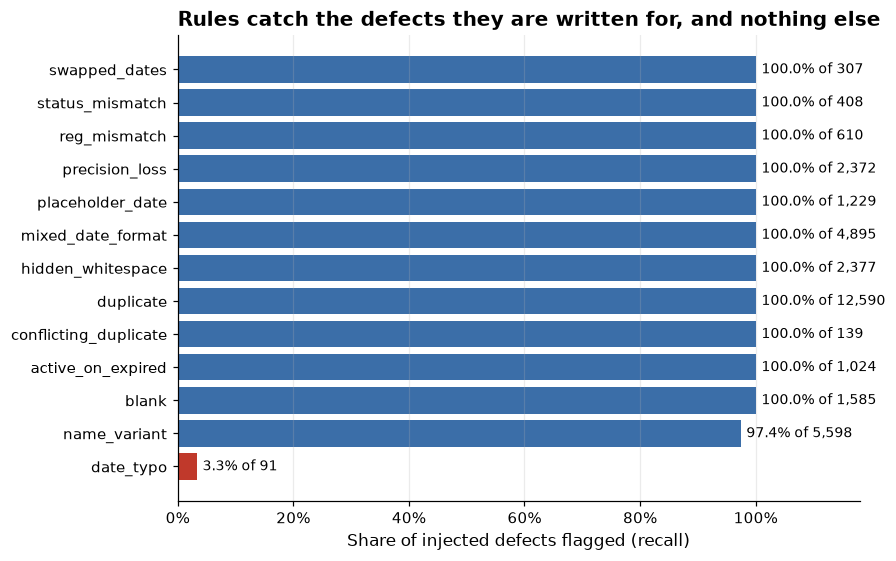

In [6]:
order = detected.drop("All defects").sort_values("recall")
fig, ax = plt.subplots(figsize=(8, 5.5))
colours = [style.HIGHLIGHT if r < 0.5 else style.ACCENT for r in order["recall"]]
ax.barh(order.index, order["recall"], color=colours)
for y, (r, n) in enumerate(zip(order["recall"], order["injected"], strict=True)):
    ax.text(min(r, 1) + 0.01, y, f"{r:.1%} of {n:,}", va="center", fontsize=9)
ax.set_xlim(0, 1.18)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of injected defects flagged (recall)")
ax.set_title("Rules catch the defects they are written for, and nothing else")
ax.grid(axis="y", visible=False)
style.save(fig, "detection_by_defect");

## 4. Matching company names

Each spelling is reduced to a matching key (upper case, punctuation and the legal suffix removed,
abbreviations such as SERVS and LOGS expanded), then keys join a cluster when their rapidfuzz similarity
to it reaches a threshold.

The threshold is tuned on a **second register generated with a different seed**, so the register being
reported never influences it. Pairwise F1 alone would pick 80, but between 80 and 86 two different
companies, Silvermead Logistics and Silvermead Logistics North, become one. A merge hides a customer
inside another, while a spelling left unmatched is still visible in the output, so the rule is: the best
F1 among thresholds that merge no two operators. That gives 88.

,precision,recall,f1,merged,chosen
threshold,,,,,
70,0.7808,0.9907,0.8733,14,False
72,0.8591,0.9896,0.9197,9,False
74,0.9064,0.9941,0.9482,8,False
76,0.9650,0.9994,0.9819,6,False
78,0.9774,0.9996,0.9884,4,False
80,0.9867,0.9999,0.9933,2,False
82,0.9884,0.9940,0.9912,2,False
84,0.9884,0.9940,0.9912,2,False
86,0.9899,0.9937,0.9918,2,False


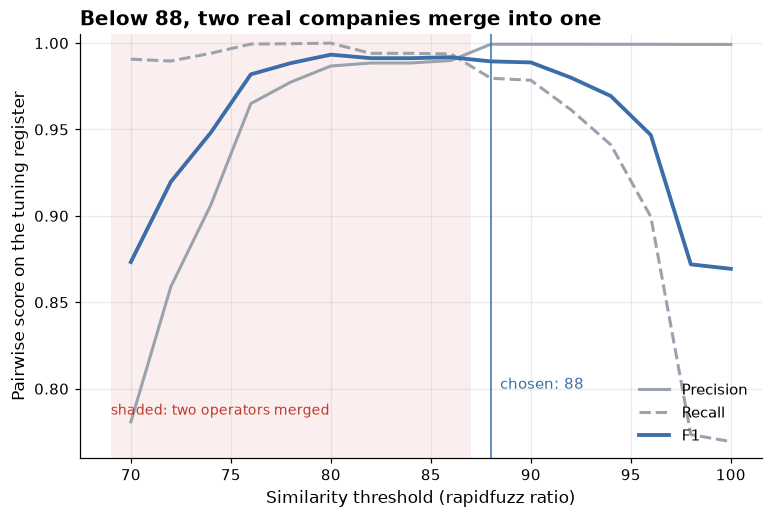

In [7]:
tuning = ev.tune_threshold(generate(seed=101))
chosen = tuning.index[tuning["chosen"]][0]

fig, ax = plt.subplots()
merged = tuning.index[tuning["merged"] > 0]
for t in merged:
    ax.axvspan(t - 1, t + 1, color=style.HIGHLIGHT, alpha=0.08, lw=0)
ax.plot(tuning.index, tuning["precision"], color=style.MUTED, lw=2, label="Precision")
ax.plot(tuning.index, tuning["recall"], color=style.MUTED, lw=2, ls="--", label="Recall")
ax.plot(tuning.index, tuning["f1"], color=style.ACCENT, lw=2.5, label="F1")
ax.axvline(chosen, color=style.ACCENT, lw=1)
ax.annotate(f"chosen: {chosen:.0f}", (chosen, 0.80), xytext=(6, 0), textcoords="offset points", color=style.ACCENT)
ax.text(merged.min() - 1, 0.785, "shaded: two operators merged", color=style.HIGHLIGHT, fontsize=9)
ax.set_ylim(0.76, 1.005)
ax.set_xlabel("Similarity threshold (rapidfuzz ratio)")
ax.set_ylabel("Pairwise score on the tuning register")
ax.set_title("Below 88, two real companies merge into one")
ax.legend(loc="lower right")
style.save(fig, "name_threshold")
tuning.round(4)

In [8]:
names = ev.name_matching(register, result.std["company"])
truth_company = ev.true_operator(register)
wrong = result.std[result.std["company"] != truth_company]
print(f"Pairwise precision {names['precision']:.1%}, recall {names['recall']:.1%}; "
      f"{names['rows_exactly_right']:.1%} of rows get exactly the right name.")
print(f"Operators merged: {ev.merged_operators(truth_company, result.std['company']) or 'none'}")
pd.DataFrame({"spelling": wrong["company_raw"], "matched to": wrong["company"], "truth": truth_company[wrong.index]}).value_counts().head(8).to_frame("rows")

Pairwise precision 99.0%, recall 98.1%; 98.1% of rows get exactly the right name.
Operators merged: none


,,,rows
spelling,matched to,truth,
SILVERMEAD LOGISTICS,Silvermead Logistics Ltd,Silvermead Logistics North Ltd,71
Copperleigh Fleet Se,Copperleigh Fleet Se,Copperleigh Fleet Services Ltd,33
Silvermead Logistics,Silvermead Logistics Ltd,Silvermead Logistics North Ltd,21
Hartwyn HLG Lttd,Hartwyn HLG Lttd,Hartwyn Haulage Ltd,20
Gildersby Freihgt Lt,Gildersby Freihgt Lt,Gildersby Freight Ltd,19
Fernhollow DIIST Ltd,Fernhollow DIIST Ltd,Fernhollow Distribution Ltd,17
Hartwyn LLOGS Ltd,Hartwyn LLOGS Ltd,Hartwyn Logistics Ltd,16
Copperleigh Fleet SE,Copperleigh Fleet Se,Copperleigh Fleet Services Ltd,15


Most misses are spellings that stayed in a cluster of their own: truncated and misspelt at once
("Copperleigh Fleet Se", "Gildersby Freihgt Lt"). They are visible, and one review of the cluster list
would fix them. The serious miss is different: "Silvermead Logistics North Ltd", cut to the 20 character
field limit, becomes exactly "Silvermead Logistics", the other company's name. No similarity measure can
tell them apart, because the information is gone. Section 5 recovers most of these rows anyway, because a
card's other rows usually carry the full name.

## 5. Collapsing duplicates

The card number is the natural key, but Excel stores only 15 significant digits, so a rounded number
loses its last three digits, and cards on one account share their first fifteen. A rounded number is
matched back only when exactly one intact number has the same first fifteen digits **and** the same
vehicle registration.

Survivorship, which value wins for each field:

* **Status** comes from the latest row, because status is the field that changes over a card's life.
* **Every other field** takes the most common value across the card's rows, so one bad row is outvoted.
  Ties go to the latest row.
* **Rows the Isolation Forest flags** only vote when no other row can.

In [9]:
res = ev.resolution(register, result.keys)
rows_by_status = result.keys["number_status"].value_counts()
print(f"{len(raw):,} rows resolved to {res['resolved_cards']:,} records; there are {res['true_cards']:,} real cards.")
print(f"Pairwise precision {res['precision']:.1%}, recall {res['recall']:.1%}.")
print(f"Rows with a rounded number: {rows_by_status.get('recovered', 0):,} recovered, "
      f"{rows_by_status.get('unrecoverable', 0):,} unrecoverable ({res['unrecoverable_numbers']} cards where every copy was rounded).")
conflicted = register.defects.loc[register.defects["defect"] == "conflicting_duplicate", "card_id"].unique()
after = ev.accuracy_after(register, result.golden, result.keys)
print(f"Cards whose copies disagreed on status: {len(conflicted)}; status correct after survivorship for all cards: {after['status_code']:.1%}")

16,090 rows resolved to 3,500 records; there are 3,500 real cards.
Pairwise precision 100.0%, recall 100.0%.
Rows with a rounded number: 2,331 recovered, 48 unrecoverable (28 cards where every copy was rounded).
Cards whose copies disagreed on status: 91; status correct after survivorship for all cards: 100.0%


## 6. What the rules miss

The year typos are valid dates in the right format, so every rule passes them. They are unusual, though:
a card valid for 47 years instead of two or three. An Isolation Forest over five date features (validity
length, lead time, card age, update lag, time to expiry) scores how easily each row is isolated. Flagging
the top 1% for review, about 160 rows, is a budget a person could check in an hour.

Flagged 161 rows; 88 of the 91 typos are among them.
The other 73 flagged rows: 57 carry some other defect, 16 are clean rows that are simply unusual.


Typos the forest misses: 3; all of them caught by the date exists rule: True


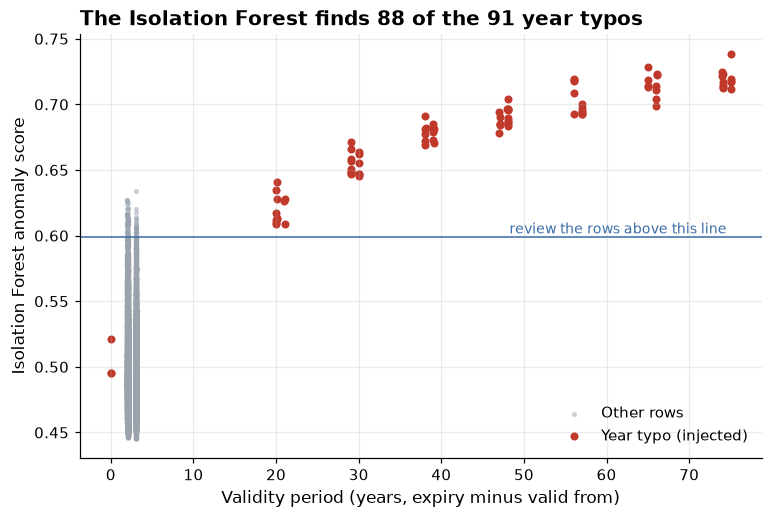

In [10]:
an = result.anomalies
typo_rows = register.defects.loc[register.defects["defect"] == "date_typo", "row_id"]
is_typo = an.index.isin(typo_rows)
flagged = an["anomalous"]
other_defect = an.index.isin(register.defects.loc[register.defects["defect"] != "duplicate", "row_id"])
print(f"Flagged {flagged.sum()} rows; {(flagged & is_typo).sum()} of the {is_typo.sum()} typos are among them.")
print(f"The other {(flagged & ~is_typo).sum()} flagged rows: {(flagged & ~is_typo & other_defect).sum()} carry some other "
      f"defect, {(flagged & ~is_typo & ~other_defect).sum()} are clean rows that are simply unusual.")

fig, ax = plt.subplots()
years = an["validity_days"] / 365.25
ax.scatter(years[~is_typo], an.loc[~is_typo, "score"], s=6, color=style.MUTED, alpha=0.4, label="Other rows")
ax.scatter(years[is_typo], an.loc[is_typo, "score"], s=18, color=style.HIGHLIGHT, label="Year typo (injected)")
cut = an.loc[flagged, "score"].min()
ax.axhline(cut, color=style.ACCENT, lw=1)
ax.text(years.max(), cut, "review the rows above this line ", ha="right", va="bottom", color=style.ACCENT, fontsize=9)
ax.set_xlabel("Validity period (years, expiry minus valid from)")
ax.set_ylabel("Isolation Forest anomaly score")
ax.set_title(f"The Isolation Forest finds {(flagged & is_typo).sum()} of the {is_typo.sum()} year typos")
ax.legend(loc="lower right")
style.save(fig, "anomalies")
caught_by_rule = set(result.flags.loc[result.flags["defect"] == "date_typo", "row_id"])
missed = set(typo_rows[~typo_rows.isin(an.index[flagged])])
print(f"Typos the forest misses: {len(missed)}; all of them caught by the date exists rule: {missed <= caught_by_rule}")

The three typos the forest misses sit at zero years: they are the impossible dates, which cannot be read,
so their validity period is unknown. The rule catches exactly those. Between them, the rules and the
forest find every typo.

The flags matter twice. They give a reviewer a short list, and they feed survivorship: a flagged row's
expiry is ignored when the card has another row. Without that, cards whose only copies include a typo
would keep it:

In [11]:
without, without_keys, _ = resolve(result.fixed)
acc_without = ev.accuracy_after(register, without, without_keys)
n = len(register.truth)
print(f"Cards with the wrong expiry: {round((1 - acc_without['expiry_date']) * n)} without the forest's flags, "
      f"{round((1 - after['expiry_date']) * n)} with them.")

Cards with the wrong expiry: 2 without the forest's flags, 0 with them.


## 7. Before and after

The scorecard reports the share of rows that pass every rule in each dimension. Before is the extract
as delivered, with the pipeline's own detection; after is the same rules run on the cleaned register.

,Before,After
Completeness,90.4%,98.6%
Validity,32.3%,100.0%
Uniqueness,21.8%,100.0%
Consistency,91.2%,100.0%
Timeliness,93.6%,100.0%


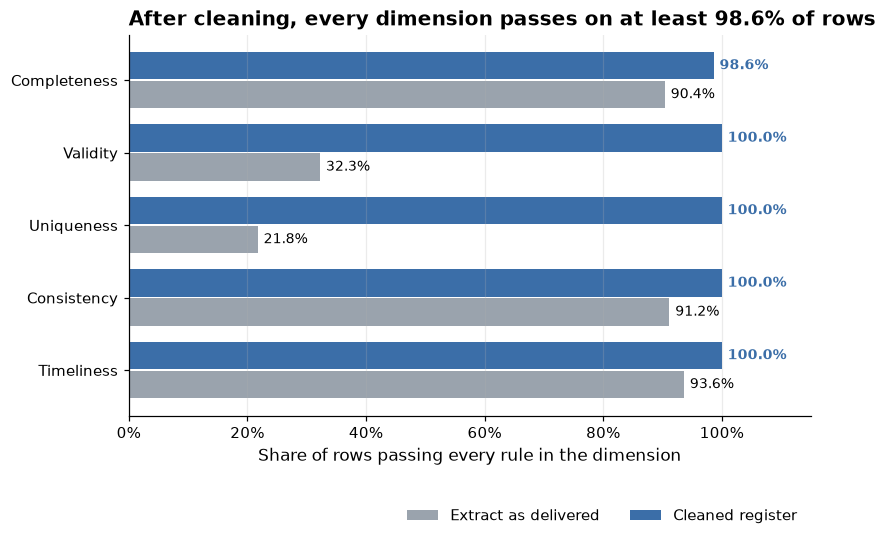

In [12]:
cards = result.scorecards(len(raw))
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(cards))
ax.barh(y + 0.2, cards["Before"], height=0.38, color=style.BEFORE, label="Extract as delivered")
ax.barh(y - 0.2, cards["After"], height=0.38, color=style.AFTER, label="Cleaned register")
for i, (b, a) in enumerate(zip(cards["Before"], cards["After"], strict=True)):
    ax.text(b + 0.01, i + 0.2, f"{b:.1%}", va="center", fontsize=9)
    ax.text(a + 0.01, i - 0.2, f"{a:.1%}", va="center", fontsize=9, color=style.AFTER, fontweight="bold")
ax.set_yticks(y, cards.index)
ax.invert_yaxis()
ax.set_xlim(0, 1.15)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of rows passing every rule in the dimension")
ax.set_title(f"After cleaning, every dimension passes on at least {cards['After'].min():.1%} of rows")
ax.legend(loc="lower right", bbox_to_anchor=(1, -0.32), ncol=2)
ax.grid(axis="y", visible=False)
style.save(fig, "scorecard")
cards.map("{:.1%}".format)

A scorecard can be gamed: blanking a bad value improves validity. So the stronger test compares each
field with the truth. The cleaned register has one record per card; each is compared field by field with
the card it came from.

,Extract,Cleaned
company,63.34%,99.69%
valid_from,82.91%,99.71%
status_description,84.09%,100.00%
card_number,85.26%,99.20%
expiry_date,87.46%,100.00%
created_date,88.19%,100.00%
status_code,92.77%,100.00%
restriction_code,93.98%,99.66%
fuel_network,96.95%,100.00%
vehicle_reg,97.02%,100.00%


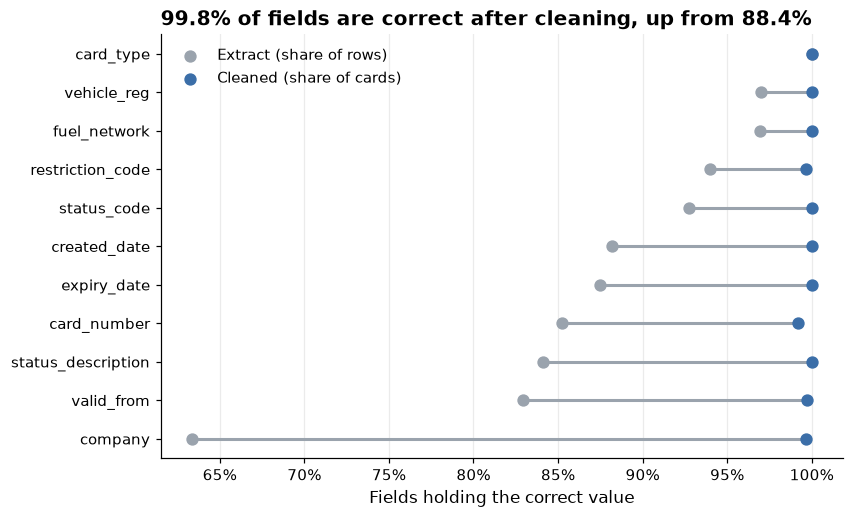

In [13]:
before = ev.accuracy_before(register)
accuracy = pd.DataFrame({"Extract": before, "Cleaned": after}).sort_values("Extract")
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(accuracy))
ax.hlines(y, accuracy["Extract"], accuracy["Cleaned"], color=style.MUTED, lw=2)
ax.scatter(accuracy["Extract"], y, color=style.BEFORE, s=50, zorder=3, label="Extract (share of rows)")
ax.scatter(accuracy["Cleaned"], y, color=style.AFTER, s=50, zorder=3, label="Cleaned (share of cards)")
ax.set_yticks(y, accuracy.index)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Fields holding the correct value")
ax.set_title(f"{after.mean():.1%} of fields are correct after cleaning, up from {before.mean():.1%}")
ax.legend(loc="upper left")
ax.grid(axis="y", visible=False)
style.save(fig, "field_accuracy")
accuracy.map("{:.2%}".format)

In [14]:
left = result.golden_flags.groupby(["column", "defect"]).size().rename("records")
left.to_frame()

,,records
column,defect,
card_number,blank,28
restriction_code,blank,12
valid_from,blank,10


What is left is what cannot be known from the data:

* **28 card numbers** where every copy was rounded by Excel. The cards are still collapsed correctly
  (by prefix and registration) but the last three digits are gone and are left blank, not guessed.
* **Restriction codes** blank in every copy of a card.
* **Valid from dates** that were the 01/01/1990 placeholder in every copy.

Leaving these blank and flagged is a choice: a guessed value would score better on completeness and be
wrong.

## 8. Excel against the pipeline

The original apprenticeship challenge was cleaned by hand in Excel. The honest comparison:

| | Hand cleaning in Excel | This pipeline |
|---|---|---|
| Time | Hours for one file, and the same again next month | Seconds per run once written; writing it took days |
| Repeatability | Depends on remembering every step | Same input, same output, every time |
| Auditability | Edits overwrite the original | Raw file untouched; every flag and fix logged with its rule |
| Card numbers | Opening the file can itself cause the 15 digit rounding | Read as text, so the damage cannot happen here |
| Judgement calls | Made case by case, often inconsistently | Written down once as survivorship rules |
| Unknown problems | A person may notice something odd | Only what rules or the anomaly model look for |
| Measurement | No way to know how accurate the result is | Scored against ground truth |

Excel is still the faster tool for a one off look at a small file. The pipeline wins once the file
recurs, is large, or the result has to be trusted by someone else.

## 9. Limitations

* **The generator and the pipeline share an author.** The defect types are known in advance, so the
  rule scores are an upper bound. The fair tests are the parts that do not depend on that knowledge:
  the name threshold (tuned on a separate register), number recovery, and the anomaly model's results.
* **Synthetic data is cleaner than real data.** Real registers have defects nobody listed, and defects
  that interact in more ways than these.
* **The abbreviation list** was written from the variants, as an analyst would after profiling. A new
  abbreviation would fall to the fuzzy matcher, which handles some and not others.
* **The Isolation Forest finds what is unusual, not what is wrong.** It catches the year typos because
  they are extreme; a typo of one year would look normal.